# التحليل الاستكشافي للصفقات العقارية

نبدأ من ملف البيانات المنظفة ونشوف كيف تتوزع الأسعار، وعلاقتها بالمساحة والموقع ونوع العقار.
السعر هنا هو سعر الصفقة كاملة، وقد تضم الصفقة أكثر من عقار.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

figures_folder = Path("../reports/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_csv("../data/cleaned/clean.csv")

df.head()

,المنطقة,المدينة,المدينة / الحي,الرقم المرجعي للصفقة,تاريخ الصفقة ميلادي,تاريخ الصفقة هجري,تصنيف العقار,عدد العقارات,السعر,المساحة,سعر_المتر
0,منطقة مكة المكرمه,الطائف,الطائف/ الكدى,35983585,2026/04/01,1447/10/13,سكني,1,1000000.0,593.75,1684.210526
1,منطقة الرياض,حوطة بني تميم,حوطة بني تميم/ الورود,35979045,2026/04/01,1447/10/13,سكني,1,1115626.0,575.00,1940.219130
2,منطقة مكة المكرمه,الطائف,الطائف/ الحلقة الشرقية,35986850,2026/04/01,1447/10/13,سكني,1,600000.0,307.74,1949.697797
3,منطقة مكة المكرمه,الطائف,الطائف/ اليمانيه,35984449,2026/04/01,1447/10/13,سكني,1,245000.0,179.79,1362.700929
4,منطقة الرياض,الدلم,الدلم/ الفيصلية,35972886,2026/04/01,1447/10/13,سكني,1,120000.0,500.00,240.000000


In [3]:
transaction_dates = pd.to_datetime(df["تاريخ الصفقة ميلادي"], format="%Y/%m/%d")

print("عدد الصفقات:", len(df))
print("بداية الفترة:", transaction_dates.min().date())
print("نهاية الفترة:", transaction_dates.max().date())

df[["السعر", "المساحة", "عدد العقارات", "سعر_المتر"]].describe().round(2)

عدد الصفقات: 34279
بداية الفترة: 2026-04-01
نهاية الفترة: 2026-06-30


,السعر,المساحة,عدد العقارات,سعر_المتر
count,3.427900e+04,34279.00,34279.00,34279.00
mean,9.136836e+05,8629.63,1.01,1707.10
std,1.068888e+07,136540.30,0.30,2691.07
min,5.000000e+03,0.24,1.00,0.00
25%,1.075000e+05,258.68,1.00,201.01
50%,3.800000e+05,441.32,1.00,850.00
75%,7.300000e+05,656.70,1.00,2545.06
max,1.260263e+09,8873222.00,18.00,83333.33


In [4]:
# نتأكد أن القيم تصلح للرسم اللوغاريتمي بدون حذف أي صف.
plot_values = df[["السعر", "المساحة", "سعر_المتر"]]

assert np.isfinite(plot_values).all().all(), "راجع القيم الناقصة أو غير المحدودة في ملف التنظيف"
assert (plot_values > 0).all().all(), "الرسم اللوغاريتمي يحتاج قيماً أكبر من صفر"

print("القيم الناقصة:", df.isna().sum().sum())
print("الصفوف المكررة:", df.duplicated().sum())

القيم الناقصة: 0
الصفوف المكررة: 0


الملف فيه 34,279 صفقة من أبريل إلى يونيو 2026. بنستخدم البيانات كما هي؛ أي تعديل على التنظيف يكون في دفتر `01_cleaning.ipynb`.

اعتبرنا السعر بالريال والمساحة بالمتر المربع، لكن الملف نفسه ما يذكر الوحدات، فنحتاج نتأكد منها من المصدر.

## 1. توزيع السعر

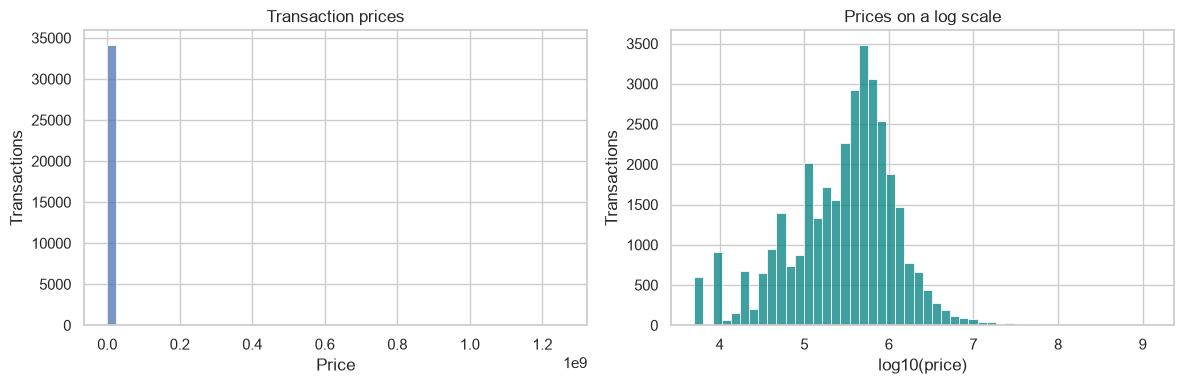

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["السعر"], bins=50, ax=axes[0])
axes[0].set_title("Transaction prices")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Transactions")

sns.histplot(np.log10(df["السعر"]), bins=50, ax=axes[1], color="teal")
axes[1].set_title("Prices on a log scale")
axes[1].set_xlabel("log10(price)")
axes[1].set_ylabel("Transactions")

plt.tight_layout()
plt.savefig(figures_folder / "01_price_distribution.png", dpi=150)
plt.show()

أغلب الأسعار متجمعة في بداية الرسم الأول، وعدد قليل من الصفقات الكبيرة يسحب التوزيع لليمين. المتوسط حوالي 914 ألف والوسيط 380 ألف؛ بعد أخذ اللوغاريتم صار توزيع أغلب الصفقات أوضح.

## 2. توزيع المساحة

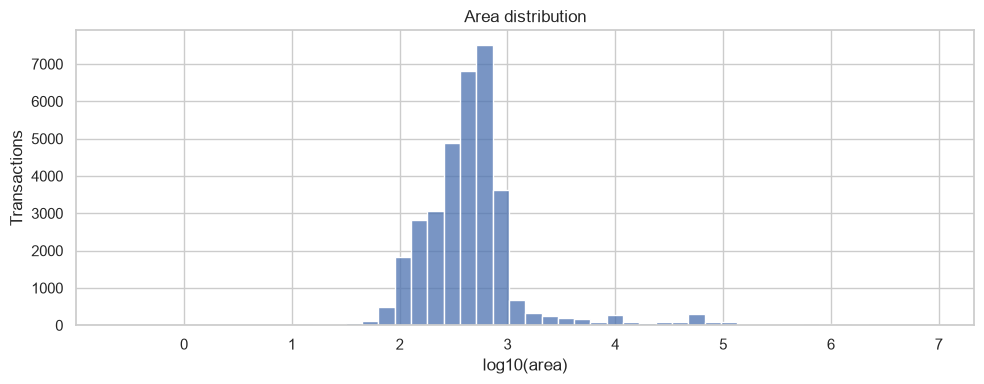

In [6]:
plt.figure(figsize=(10, 4))

sns.histplot(np.log10(df["المساحة"]), bins=50)
plt.title("Area distribution")
plt.xlabel("log10(area)")
plt.ylabel("Transactions")

plt.tight_layout()
plt.show()

وسيط المساحة حوالي 441، لكن أكبر مساحة تتجاوز 8.8 مليون. استخدمنا اللوغاريتم عشان نقدر نشوف تجمع المساحات الصغيرة والمتوسطة مع بقاء الصفقات الكبيرة في الرسم.

## 3. عدد العقارات في الصفقة

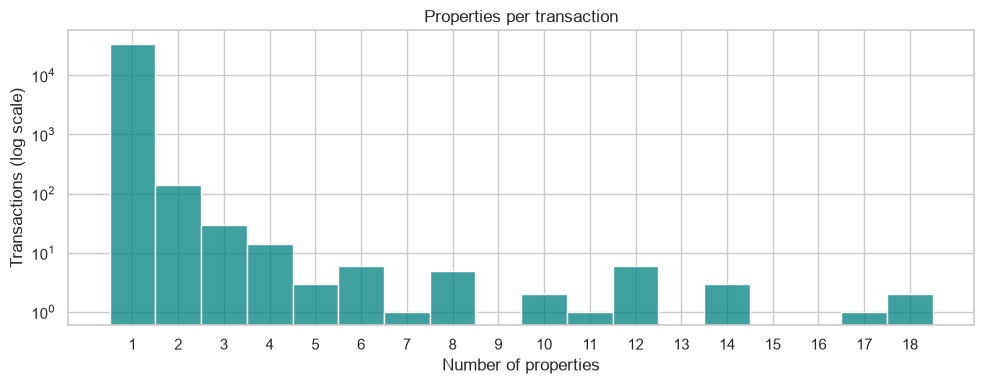

نسبة صفقات العقار الواحد: 99.37%


In [7]:
plt.figure(figsize=(10, 4))

sns.histplot(df["عدد العقارات"], discrete=True, color="teal")
plt.yscale("log")
plt.xticks(range(1, int(df["عدد العقارات"].max()) + 1))
plt.title("Properties per transaction")
plt.xlabel("Number of properties")
plt.ylabel("Transactions (log scale)")

plt.tight_layout()
plt.show()

single_property_share = df["عدد العقارات"].eq(1).mean() * 100
print(f"نسبة صفقات العقار الواحد: {single_property_share:.2f}%")

حوالي 99.37% من الصفقات فيها عقار واحد، وأكبر صفقة من ناحية العدد فيها 18 عقاراً. استخدمنا مقياساً لوغاريتمياً للتكرار لأن باقي الأعداد قليلة جداً مقارنة بصفقات العقار الواحد.

## 4. توزيع سعر المتر

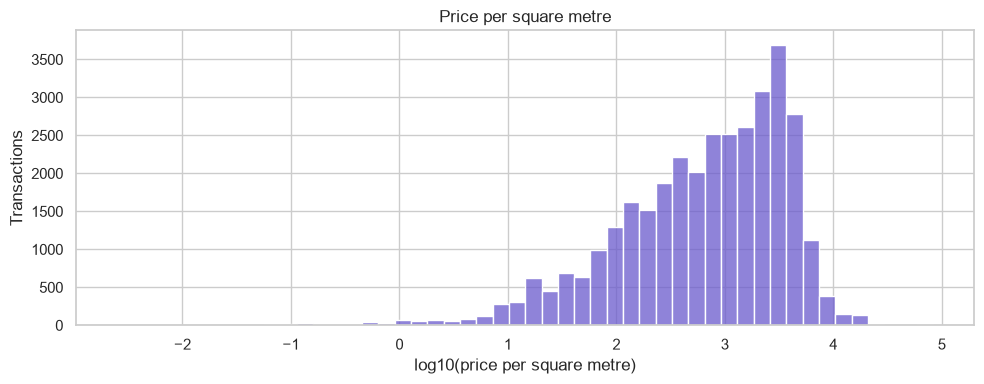

In [8]:
plt.figure(figsize=(10, 4))

sns.histplot(np.log10(df["سعر_المتر"]), bins=50, color="slateblue")
plt.title("Price per square metre")
plt.xlabel("log10(price per square metre)")
plt.ylabel("Transactions")

plt.tight_layout()
plt.show()

وسيط سعر المتر 850، ومع ذلك التوزيع فيه فرق كبير بين الطرفين. هذا المتغير مفيد للمقارنة، لكنه محسوب من السعر نفسه، فما نستخدمه لاحقاً كمدخل لنموذج يتوقع السعر.

## 5. هل المساحة الأكبر تعني سعراً أعلى؟

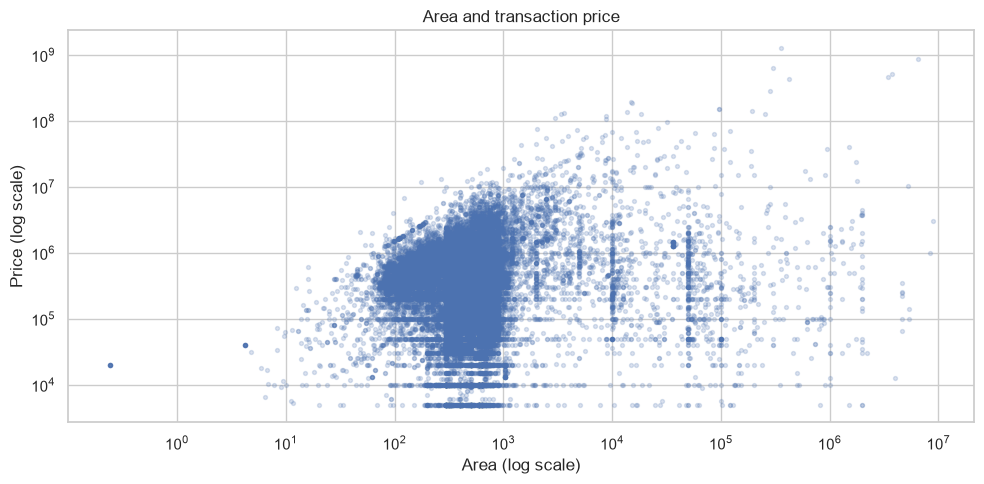

In [9]:
plt.figure(figsize=(10, 5))

plt.scatter(df["المساحة"], df["السعر"], alpha=0.2, s=8)
plt.xscale("log")
plt.yscale("log")
plt.title("Area and transaction price")
plt.xlabel("Area (log scale)")
plt.ylabel("Price (log scale)")

plt.tight_layout()
plt.savefig(figures_folder / "02_area_price.png", dpi=150)
plt.show()

فيه فرق كبير في السعر حتى بين الصفقات ذات المساحة المتقاربة. ارتباط سبيرمان بين المساحة والسعر حوالي 0.014 فقط في العينة كلها، وهذا يخلينا ننظر للموقع وتصنيف العقار قبل ما نحكم على العلاقة.

## 6. مقارنة الأسعار بين المدن
اخترنا أكثر عشر مدن من ناحية عدد الصفقات. الأسماء الإنجليزية في الرسم فقط، وأسماء المدن الأصلية باقية في البيانات.

In [10]:
top_cities = df["المدينة"].value_counts().head(10).index
city_data = df[df["المدينة"].isin(top_cities)].copy()

city_names = {
    "جده": "Jeddah",
    "المدينة المنورة": "Madinah",
    "الرياض": "Riyadh",
    "مكة المكرمة": "Makkah",
    "الدمام": "Dammam",
    "حائل": "Hail",
    "الخبر": "Khobar",
    "بريده": "Buraidah",
    "حفر الباطن": "Hafar Al Batin",
    "الطائف": "Taif",
}

city_data["City"] = city_data["المدينة"].replace(city_names)
city_order = [city_names.get(city, city) for city in top_cities]

city_coverage = len(city_data) / len(df) * 100
print(f"المدن المعروضة تغطي {city_coverage:.1f}% من صفقات الملف")

city_summary = city_data.groupby("City")["السعر"].agg(["count", "median"])
city_summary.sort_values("median")

المدن المعروضة تغطي 52.4% من صفقات الملف


,count,median
City,,
Hafar Al Batin,1020,100000.0
Hail,1088,230000.0
Buraidah,1050,240000.0
Taif,991,450000.0
Madinah,2315,454555.0
Makkah,1366,501539.0
Jeddah,6202,599050.0
Riyadh,1673,684317.0
Dammam,1165,698400.0


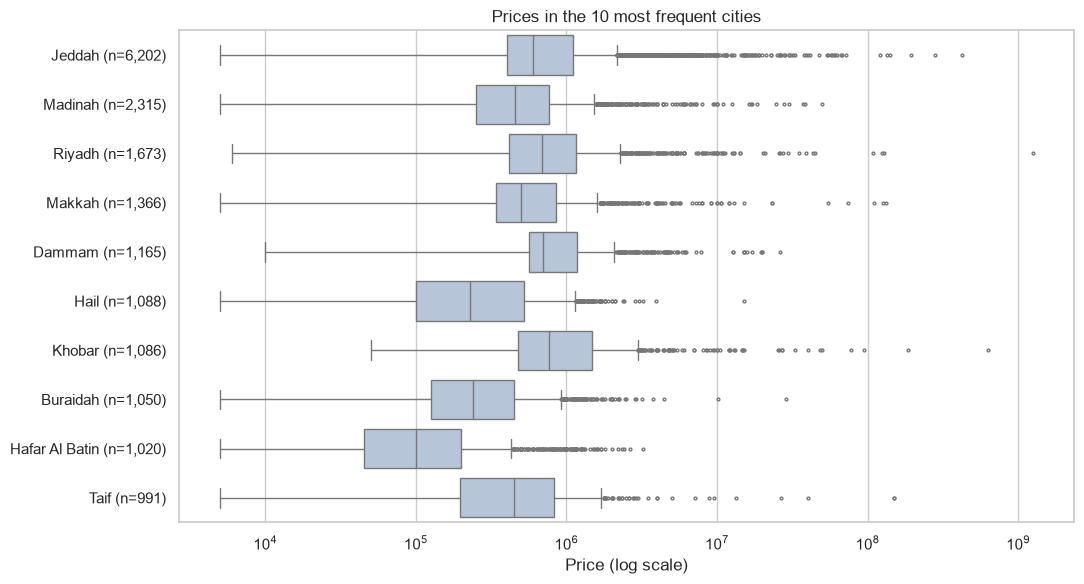

In [11]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=city_data,
    x="السعر",
    y="City",
    order=city_order,
    color="lightsteelblue",
    fliersize=2,
)

city_labels = [
    f"{city} (n={city_summary.loc[city, 'count']:,})"
    for city in city_order
]
plt.yticks(range(len(city_order)), city_labels)

plt.xscale("log")
plt.title("Prices in the 10 most frequent cities")
plt.xlabel("Price (log scale)")
plt.ylabel("")

plt.tight_layout()
plt.savefig(figures_folder / "03_city_price.png", dpi=150)
plt.show()

بين المدن المعروضة، الخبر عندها أعلى وسيط للسعر (762,500)، وحفر الباطن أقل وسيط (100,000). هذه المدن تغطي 52.4% من صفقات الملف، والمقارنة ما تثبّت المساحة أو نوع العقار؛ لذلك ما نعتبرها ترتيباً لأغلى مدن المملكة.

## 7. الارتباط بين المتغيرات
نقارن بيرسون وسبيرمان لأن عندنا قيماً كبيرة وتوزيعات ملتوية. رقم الصفقة مجرد معرّف، لذلك ما دخلناه في المقارنة.

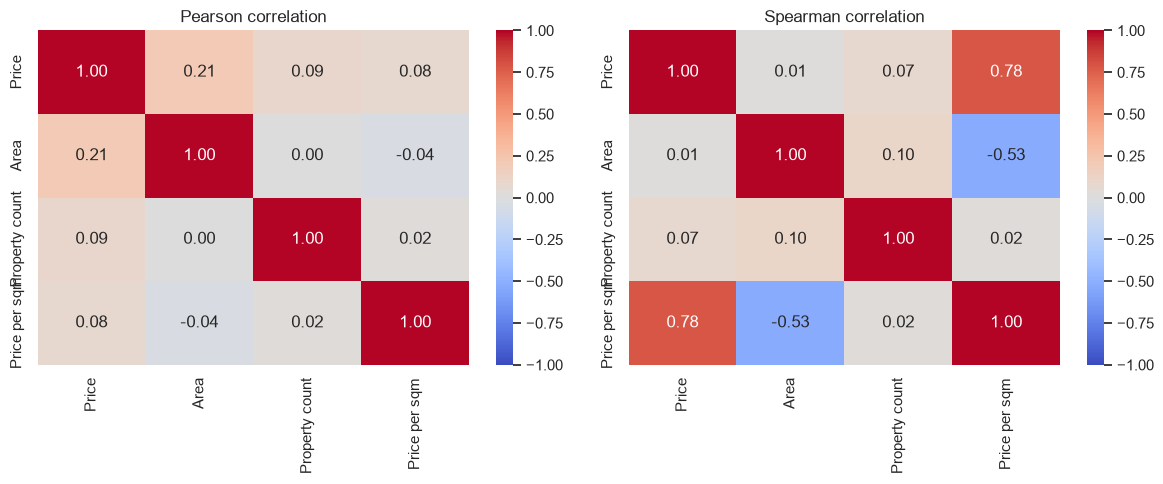

In [12]:
numeric_data = df[["السعر", "المساحة", "عدد العقارات", "سعر_المتر"]].copy()
numeric_data.columns = ["Price", "Area", "Property count", "Price per sqm"]

pearson_corr = numeric_data.corr(method="pearson")
spearman_corr = numeric_data.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0],
)
axes[0].set_title("Pearson correlation")

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title("Spearman correlation")

plt.tight_layout()
plt.show()

أوضح ارتباط في سبيرمان هو بين السعر وسعر المتر (0.78)، لكن الاثنين مو مستقلين لأن السعر يدخل في حساب سعر المتر. ارتباط المساحة بالسعر يختلف بين بيرسون (0.21) وسبيرمان (0.01)؛ الأول يقيس العلاقة الخطية والثاني يقارن ترتيب القيم، والفرق وحده ما يثبت سبب العلاقة.

## 8. شيء لفت انتباهنا: المساحات الزراعية وسعر المتر

In [13]:
property_summary = df.groupby("تصنيف العقار").agg(
    transactions=("السعر", "size"),
    median_area=("المساحة", "median"),
    median_price_per_sqm=("سعر_المتر", "median"),
)

property_summary = property_summary.rename(index={
    "سكني": "Residential",
    "تجاري": "Commercial",
    "زراعي": "Agricultural",
})

property_summary.round(2)

,transactions,median_area,median_price_per_sqm
تصنيف العقار,,,
Commercial,1723,660.0,1308.22
Agricultural,1367,36560.0,14.29
Residential,31189,405.0,900.00


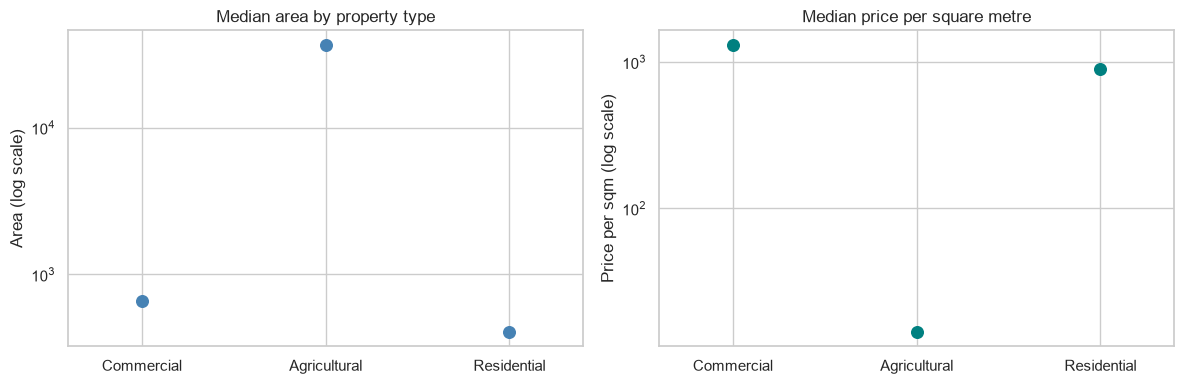

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
positions = range(len(property_summary))

axes[0].scatter(positions, property_summary["median_area"], s=70, color="steelblue")
axes[0].set_xticks(positions, property_summary.index)
axes[0].set_title("Median area by property type")
axes[0].set_ylabel("Area (log scale)")
axes[0].set_yscale("log")
axes[0].margins(x=0.2)

axes[1].scatter(positions, property_summary["median_price_per_sqm"], s=70, color="teal")
axes[1].set_xticks(positions, property_summary.index)
axes[1].set_title("Median price per square metre")
axes[1].set_ylabel("Price per sqm (log scale)")
axes[1].set_yscale("log")
axes[1].margins(x=0.2)

plt.tight_layout()
plt.show()

العقارات الزراعية عندها أكبر وسيط للمساحة (36,560)، وأقل وسيط لسعر المتر (حوالي 14)، مقارنة بـ900 للسكني و1,308 للتجاري. عشان نشوف هل اختلاف الأنواع يفسر العلاقة الضعيفة، نحسب الارتباط داخل كل نوع أيضاً.

In [15]:
type_correlations = []

for property_type, transactions in df.groupby("تصنيف العقار"):
    correlation = transactions[["المساحة", "السعر"]].corr(method="spearman")

    type_correlations.append({
        "تصنيف العقار": property_type,
        "عدد الصفقات": len(transactions),
        "ارتباط المساحة بالسعر": correlation.loc["المساحة", "السعر"],
    })

pd.DataFrame(type_correlations).round(3)

,تصنيف العقار,عدد الصفقات,ارتباط المساحة بالسعر
0,تجاري,1723,0.423
1,زراعي,1367,-0.112
2,سكني,31189,-0.044


الارتباط في التجاري حوالي 0.423، مقابل -0.044 في السكني و-0.112 في الزراعي. يعني العلاقة تختلف حسب التصنيف، لكن فصل الأنواع ما كشف علاقة موجبة واضحة في كل نوع؛ ما نقدر ننسب النتيجة كلها لخلط الأنواع.

## ملاحظات نرجع لها لاحقاً

- الوسيط يصف منتصف الأسعار، بينما المتوسط يتأثر بالصفقات الكبيرة جداً.
- مقارنة المدن ما تعزل أثر الموقع عن المساحة والتصنيف. كذلك، البيانات تغطي ثلاثة أشهر فقط.
- أصغر مساحة مسجلة هي 0.24. نحتاج نراجع مصدر هذه الصفقة قبل تفسيرها؛ تركناها كما هي في التحليل.
- قواعد التنظيف استبعدت 385 صفقة. أي قرار بتغيير هذه القواعد نراجعه مع الفريق أولاً.

حفظنا رسوم توزيع السعر، وعلاقة المساحة بالسعر، ومقارنة المدن في `reports/figures` لاستخدامها في العرض.